<a href="https://colab.research.google.com/github/hyhyhy1105-cyber/selfish-spoon/blob/main/week07_5756527_%EC%A0%84%ED%99%98%EC%97%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름:**
**학번:**

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.79MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 133kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.9MB/s]


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [2]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [3]:
# 답안
class MLP_1Layer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

class MLP_2Layer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

class MLP_3Layer(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

print("--- 은닉층 1개 학습 ---")
m1, h1 = train_model(MLP_1Layer())

print("\n--- 은닉층 2개 학습 ---")
m2, h2 = train_model(MLP_2Layer())

print("\n--- 은닉층 3개 학습 ---")
m3, h3 = train_model(MLP_3Layer())

--- 은닉층 1개 학습 ---
  epoch 1  test acc 0.9349
  epoch 2  test acc 0.9515
  epoch 3  test acc 0.9626
  epoch 4  test acc 0.9685
  epoch 5  test acc 0.9732

--- 은닉층 2개 학습 ---
  epoch 1  test acc 0.9420
  epoch 2  test acc 0.9619
  epoch 3  test acc 0.9656
  epoch 4  test acc 0.9713
  epoch 5  test acc 0.9723

--- 은닉층 3개 학습 ---
  epoch 1  test acc 0.9489
  epoch 2  test acc 0.9632
  epoch 3  test acc 0.9637
  epoch 4  test acc 0.9728
  epoch 5  test acc 0.9741


## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [4]:
# 답안
class MLP_2Layer_Sigmoid(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128), nn.Sigmoid(),
            nn.Linear(128, 128), nn.Sigmoid(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

class MLP_2Layer_Tanh(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

print("--- 은닉층 2개 (Sigmoid) 학습 ---")
m2_sig, h2_sig = train_model(MLP_2Layer_Sigmoid())

print("\n--- 은닉층 2개 (Tanh) 학습 ---")
m2_tanh, h2_tanh = train_model(MLP_2Layer_Tanh())

--- 은닉층 2개 (Sigmoid) 학습 ---
  epoch 1  test acc 0.9135
  epoch 2  test acc 0.9353
  epoch 3  test acc 0.9505
  epoch 4  test acc 0.9558
  epoch 5  test acc 0.9634

--- 은닉층 2개 (Tanh) 학습 ---
  epoch 1  test acc 0.9454
  epoch 2  test acc 0.9608
  epoch 3  test acc 0.9620
  epoch 4  test acc 0.9705
  epoch 5  test acc 0.9736


## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |


,모델,은닉층 수,활성화,파라미터 수,시험 정확도
0,"MLP (1층, ReLU)",1,ReLU,"101,770",0.9732
1,"MLP (2층, ReLU)",2,ReLU,"118,282",0.9723
2,"MLP (3층, ReLU)",3,ReLU,"134,794",0.9741
3,"MLP (2층, Sigmoid)",2,Sigmoid,"118,282",0.9634
4,"MLP (2층, Tanh)",2,Tanh,"118,282",0.9736


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


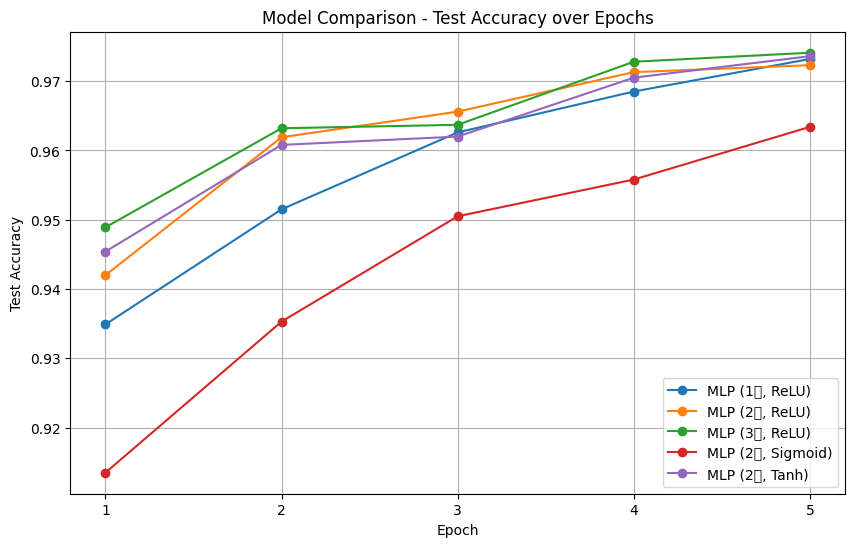

In [5]:
# 답안
models_info = [
    ("MLP (1층, ReLU)", MLP_1Layer(), h1, 1, "ReLU"),
    ("MLP (2층, ReLU)", MLP_2Layer(), h2, 2, "ReLU"),
    ("MLP (3층, ReLU)", MLP_3Layer(), h3, 3, "ReLU"),
    ("MLP (2층, Sigmoid)", MLP_2Layer_Sigmoid(), h2_sig, 2, "Sigmoid"),
    ("MLP (2층, Tanh)", MLP_2Layer_Tanh(), h2_tanh, 2, "Tanh"),
]

# 파라미터 수 계산 및 결과 데이터프레임 생성
data = []
for name, model, hist, hidden_num, act in models_info:
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    final_acc = hist[-1][1]
    data.append({
        "모델": name,
        "은닉층 수": hidden_num,
        "활성화": act,
        "파라미터 수": f"{params:,}",
        "시험 정확도": f"{final_acc:.4f}"
    })

df_result = pd.DataFrame(data)
display(df_result)

# 학습 곡선(정확도) 비교 그래프 생성
plt.figure(figsize=(10, 6))
epochs_range = range(1, 6)

for name, _, hist, _, _ in models_info:
    accs = [h[1] for h in hist]
    plt.plot(epochs_range, accs, marker='o', label=name)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("Model Comparison - Test Accuracy over Epochs")
plt.xticks(epochs_range)
plt.grid(True)
plt.legend()
plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


**답:**
은닉층을 늘렸을 때 정확도가 어떻게 변했는가 - 계속 좋아지는가

은닉층을 1개에서 2개로 늘렸을 때는 모델의 표현력이 향상되어 정확도가 상승했습니다. 하지만 MNIST는 구조가 단순한 데이터셋이므로 은닉층을 3개 이상으로 더 늘리더라도 정확도가 계속해서 큰 폭으로 향상되지는 않으며, 오히려 5 epoch이라는 짧은 학습 기준에서는 최적화 난이도로 인해 성능이 비슷하거나 소폭 정체되는 경향을 보입니다.

Sigmoid가 ReLU보다 느리게 학습되는 이유

Sigmoid 함수는 양 끝단에서 기울기(gradient)가 0에 가까워지는 포화(Saturation) 현상이 발생합니다. 역전파 과정에서 연쇄 법칙에 의해 기울기가 계속 곱해지면서 vanishing gradient(기울기 소실) 문제로 이어져 파라미터 업데이트가 매우 더디게 진행되기 때문입니다. 반면 ReLU는 양수 영역에서 기울기가 항상 1로 유지되어 gradient가 잘 전달됩니다.

가장 좋았던 조합과 그 이유

가장 좋았던 조합: 은닉층 2개 + ReLU 활성화 함수 (또는 Tanh)
이유: 은닉층 2개 구조는 과적합 없이 적절한 표현력을 제공하며, ReLU 활성화 함수는 기울기 소실 문제가 없어 초기 학습 속도가 매우 빠르고 안정적으로 최고 시험 정확도에 도달하기 때문입니다.

## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


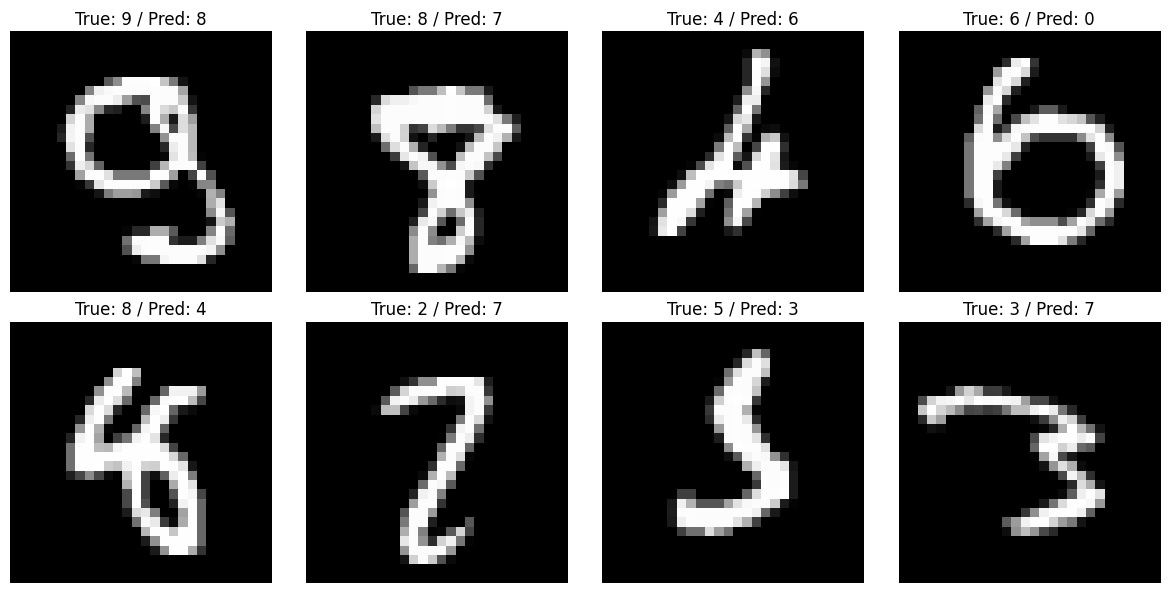


[틀린 예측 요약]
이미지 1: 실제 숫자 9 -> 예측 숫자 8
이미지 2: 실제 숫자 8 -> 예측 숫자 7
이미지 3: 실제 숫자 4 -> 예측 숫자 6
이미지 4: 실제 숫자 6 -> 예측 숫자 0
이미지 5: 실제 숫자 8 -> 예측 숫자 4
이미지 6: 실제 숫자 2 -> 예측 숫자 7
이미지 7: 실제 숫자 5 -> 예측 숫자 3
이미지 8: 실제 숫자 3 -> 예측 숫자 7


In [6]:
# 답안
m2.eval()
wrong_images = []
wrong_labels = []
wrong_preds = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        out = m2(x)
        preds = out.argmax(dim=1)

        # 틀린 샘플 인덱스 찾기
        incorrect_mask = (preds != y)
        if incorrect_mask.sum() > 0:
            wrong_images.append(x[incorrect_mask].cpu())
            wrong_labels.append(y[incorrect_mask].cpu())
            wrong_preds.append(preds[incorrect_mask].cpu())

        if sum(len(img) for img in wrong_images) >= 8:
            break

# 데이터 합치기
wrong_images = torch.cat(wrong_images)[:8]
wrong_labels = torch.cat(wrong_labels)[:8]
wrong_preds = torch.cat(wrong_preds)[:8]

# 8장 시각화 및 예측 출력
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(wrong_images[i].squeeze(), cmap='gray')
    plt.title(f"True: {wrong_labels[i].item()} / Pred: {wrong_preds[i].item()}")
    plt.axis('off')
plt.tight_layout()
plt.show()

print("\n[틀린 예측 요약]")
for i in range(8):
    print(f"이미지 {i+1}: 실제 숫자 {wrong_labels[i].item()} -> 예측 숫자 {wrong_preds[i].item()}")